# Does a persistent moisture pathway explain the shallow troughs between WY2026's episodes?

**Motivation.** Two notebooks in this mechanism thread independently found suggestive
evidence for the same underlying idea, from different angles and different scopes:

- `CA_ridging_persistence_gap_trough_depth.ipynb` found that, across the full
  1990-2025 record, a *shallower* trough in the gap between two Z500 episodes predicts
  a *longer* following episode (rho=0.51, p=0.025, n=19) -- and WY2026's own three
  gaps were shallow by history's standards, especially the gap right before March.
- `CA_ridging_persistence_central_pacific_template.ipynb` found that, *within WY2026
  only* (n=4 episodes, one season), the IVT (moisture-plume) precursor pattern feeding
  each of WY2026's four episodes was unusually self-similar to the others (91st
  percentile vs. a historical bootstrap) -- even though the dynamical (Z300) precursor
  pattern was not.

Both were read as possible signatures of "the background state never really reset
between episodes," but that connection was never tested -- the IVT-similarity metric
was only ever computed as a single one-season number (WY2026's 4 maps vs. each other),
not as a per-gap variable across history, and it was never correlated against the
gap-depth metric at all. This notebook builds that join directly: for every
fit-period gap, does the moisture pathway feeding the episode *before* the gap
resemble the one feeding the episode *after* it, and if so, does that resemblance
predict a shallower trough (or longer following episode) the same way gap depth does?

**Operationalization.** For each inter-episode gap, compute the same 5-day
pre-onset central-Pacific precursor anomaly maps used in
`CA_ridging_persistence_central_pacific_template.ipynb` for the episode immediately
preceding the gap and the episode immediately following it, and take the Pearson
correlation between the two maps (`ivt_pair_corr`) -- a direct per-gap measure of
"did the same moisture conveyor stay active across this gap." Z300 is computed the
same way as an explicit control (`z300_pair_corr`), since the template notebook found
the dynamical field does *not* show this pattern -- if the join is real, it should be
specific to IVT, not z300.

**Scope.** Z500 (ridging) episodes only, matching
`CA_ridging_persistence_central_pacific_template.ipynb`'s own scope choice. No new
fetch -- reuses `z500_t700_ca_<year>.nc` and `upstream_pacific_<year>.nc`, already in
hand.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from itertools import combinations
from scipy.stats import spearmanr, percentileofscore
import sys

import os
os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
FIT_YEARS = list(range(1990, 2026))
YEAR_2026 = 2026
ALL_YEARS = FIT_YEARS + [YEAR_2026]
THRESHOLD_SD = 1

CLIM_WINDOW = 5
MIN_DURATION = 5
MAX_GAP = 1
SIGN = 1
TROUGH_THRESH = -1.0
PRECURSOR_DAYS = 5   # matches the template/upstream notebooks' precursor window

CPAC_LAT = slice(40, 20)    # central Pacific box, descending latitude convention
CPAC_LON = slice(160, 220)  # 160E-220E (140W), same box as the template notebook

N_BOOT = 2000
rng = np.random.default_rng(42)


## 1. Build the full continuous Z500 standardized-anomaly series, 1990-2026

Same detrended calendar-day standardization as every notebook in this project
(`lib.standardize_with_trend`, fit 1990-2025, 2026 scored out-of-sample), kept as a
continuous daily series so the gaps between episodes can be examined directly. Z500
only (see scope note above).

In [2]:
def build_full_sanom():
    files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in FIT_YEARS]
    ds = xr.open_mfdataset(files, combine='by_coords', engine='netcdf4')
    weights = np.cos(np.deg2rad(ds.latitude))
    fld = ds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
    df = pd.DataFrame({'z500': fld.values}, index=pd.to_datetime(ds.time.values)).sort_index()
    df = df[df.index.month.isin([1, 2, 3, 4])]
    sanom, diag = lib.standardize_with_trend(df.index, df['z500'].values, window=CLIM_WINDOW,
                                              label='z500', verbose=False)
    df['sanom'] = sanom

    ds26 = xr.open_dataset(DATA_DIR / 'z500_t700_ca_2026.nc', engine='netcdf4')
    weights26 = np.cos(np.deg2rad(ds26.latitude))
    fld26 = ds26.z500.weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
    df26 = pd.DataFrame({'z500': fld26.values}, index=pd.to_datetime(ds26.time.values)).sort_index()
    df26 = df26[df26.index.month.isin([1, 2, 3, 4])]
    clim_mean_arr = lib.lookup_climatology(df26.index, diag['clim_mean_dict'])
    clim_std_arr = lib.lookup_climatology(df26.index, diag['clim_std_dict'])
    trend_2026 = diag['trend']['intercept'] + diag['trend']['slope'] * 2026
    df26['sanom'] = (df26['z500'] - (clim_mean_arr + trend_2026)) / clim_std_arr

    full = pd.concat([df[['sanom']], df26[['sanom']]]).sort_index()
    ep = lib.find_events(df26.index, df26['sanom'].values, threshold=1,
                          min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP)
    ep = ep[['start_date', 'end_date', 'duration_days']].reset_index(drop=True)
    return full['sanom'], ep


sanom_series, episodes_2026 = build_full_sanom()
episodes_2026['label'] = ['Jan episode', 'Late Jan/Feb episode', 'Late Feb episode', 'March (record) episode']
print(f'Z500: {len(sanom_series)} days, {len(episodes_2026)} WY2026 episodes')


Z500: 4449 days, 4 WY2026 episodes


## 2. Load the full-record Z500 event table and build one season-by-season event list

In [3]:
events = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                     parse_dates=['start_date', 'end_date'])
events['start_date'] = events.start_date.dt.date
events['end_date'] = events.end_date.dt.date
events = events[(events.threshold_sd == THRESHOLD_SD) & (events.variable == '500 hPa height (ridging)')].reset_index(drop=True)
events['year'] = events.start_date.apply(lambda d: d.year)

e26 = episodes_2026.copy()
e26['year'] = YEAR_2026
all_events = pd.concat([events[['year', 'start_date', 'end_date', 'duration_days']],
                         e26[['year', 'start_date', 'end_date', 'duration_days']]], ignore_index=True)
all_events = all_events.sort_values(['year', 'start_date']).reset_index(drop=True)
print(f'{len(all_events)} total Z500 episodes, {all_events.year.nunique()} seasons')


52 total Z500 episodes, 30 seasons


## 3. Compute gap-depth metrics for every inter-episode gap

Identical to `CA_ridging_persistence_gap_trough_depth.ipynb`'s Section 3, with one
addition: the onset date of the episode on *each side* of the gap is kept (not just
its duration), so each gap's precursor maps can be retrieved in Section 5.

In [4]:
def compute_gaps(df_events, sanom):
    rows = []
    for year, grp in df_events.groupby('year'):
        grp = grp.sort_values('start_date').reset_index(drop=True)
        for i in range(len(grp) - 1):
            gap_start = pd.Timestamp(grp.end_date[i]) + pd.Timedelta(days=1)
            gap_end = pd.Timestamp(grp.start_date[i + 1]) - pd.Timedelta(days=1)
            if gap_start > gap_end:
                continue   # back-to-back episodes (MAX_GAP already merges these; shouldn't occur)
            window = sanom.loc[gap_start:gap_end]
            rows.append({
                'year': year, 'gap_days': len(window),
                'gap_min_sanom': float(window.min()), 'gap_frac_below_neg1': float((window <= TROUGH_THRESH).mean()),
                'preceding_onset': grp.start_date[i], 'following_onset': grp.start_date[i + 1],
                'preceding_duration': grp.duration_days[i], 'following_duration': grp.duration_days[i + 1],
                'gap_start': gap_start.date(), 'gap_end': gap_end.date(),
            })
    return pd.DataFrame(rows)


gaps = compute_gaps(all_events, sanom_series)
print(f'{len(gaps)} inter-episode gaps total')
gaps[gaps.year == 2026]


22 inter-episode gaps total


,year,gap_days,gap_min_sanom,gap_frac_below_neg1,preceding_onset,following_onset,preceding_duration,following_duration,gap_start,gap_end
19,2026,10,-0.572545,0.000000,2026-01-10,2026-01-29,9,8,2026-01-19,2026-01-28
20,2026,17,-2.046280,0.294118,2026-01-29,2026-02-23,8,7,2026-02-06,2026-02-22
21,2026,9,-0.161673,0.000000,2026-02-23,2026-03-11,7,19,2026-03-02,2026-03-10


## 4. Load the central-Pacific box and build precursor anomaly maps

Identical to `CA_ridging_persistence_central_pacific_template.ipynb`'s Sections 1-2 and
2-4's `precursor_vectors` helper: same box, same exact calendar-day climatology (fit
1990-2025), same 5-day pre-onset window, same Jan-1 data-floor handling.

In [5]:
files = [DATA_DIR / f'upstream_pacific_{y}.nc' for y in ALL_YEARS]
ds = xr.open_mfdataset(files, combine='by_coords', engine='netcdf4')
ds = ds[['z300', 'viwve', 'viwvn']].sel(latitude=CPAC_LAT, longitude=CPAC_LON)
ds = ds.sel(time=ds.time.dt.month.isin([1, 2, 3, 4])).load()
ds['ivt'] = np.sqrt(ds.viwve**2 + ds.viwvn**2)
ds = ds[['z300', 'ivt']]

fit_ds = ds.sel(time=ds.time.dt.year.isin(FIT_YEARS))
climo = fit_ds.groupby(fit_ds.time.dt.strftime('%m-%d')).mean('time')
anom = ds.groupby(ds.time.dt.strftime('%m-%d')) - climo
print(f'Central Pacific box: {ds.latitude.size} x {ds.longitude.size} grid points, {ds.time.size} days, '
      f'{ALL_YEARS[0]}-{ALL_YEARS[-1]}')


def precursor_vectors(onset_date):
    onset = pd.Timestamp(onset_date)
    pre_start = onset - pd.Timedelta(days=PRECURSOR_DAYS)
    # data floor: ds only covers Jan-Apr, so a very-early-January onset's precursor
    # window would otherwise reach into unloaded December -- clip to that year's own
    # Jan 1, same convention as the template/upstream notebooks. An onset of exactly
    # Jan 1 has zero available precursor days at all -- dropped entirely below.
    data_floor = pd.Timestamp(onset.year, 1, 1)
    pre_start = max(pre_start, data_floor)
    pre_end = onset - pd.Timedelta(days=1)
    if pre_start > pre_end:
        return None, None
    window = anom.sel(time=slice(pre_start, pre_end)).mean('time')
    return window.z300.values.ravel(), window.ivt.values.ravel()


Central Pacific box: 81 x 241 grid points, 4449 days, 1990-2026


## 5. Per-gap moisture-pathway persistence: does the precursor pattern feeding the
following episode resemble the one that fed the preceding episode?

For each gap, the Pearson correlation between the preceding episode's and following
episode's precursor anomaly maps -- `ivt_pair_corr` (the hypothesis) and
`z300_pair_corr` (the control, since the template notebook found no dynamical
recurrence). Gaps where either side's precursor window is unavailable (Jan-1 onset)
are dropped.

In [6]:
def pair_corr(onset_a, onset_b):
    za, ia = precursor_vectors(onset_a)
    zb, ib = precursor_vectors(onset_b)
    if za is None or zb is None:
        return np.nan, np.nan
    return np.corrcoef(za, zb)[0, 1], np.corrcoef(ia, ib)[0, 1]


z300_pair, ivt_pair = [], []
for r in gaps.itertuples():
    zc, ic = pair_corr(r.preceding_onset, r.following_onset)
    z300_pair.append(zc)
    ivt_pair.append(ic)

gaps['z300_pair_corr'] = z300_pair
gaps['ivt_pair_corr'] = ivt_pair

n_dropped = gaps['ivt_pair_corr'].isna().sum()
print(f'{n_dropped} of {len(gaps)} gaps dropped (a Jan-1 onset on one side, zero available precursor days)')
gaps_valid = gaps.dropna(subset=['z300_pair_corr', 'ivt_pair_corr']).reset_index(drop=True)
print(f'{len(gaps_valid)} gaps with both gap-depth and pathway-persistence metrics available')
gaps_valid[gaps_valid.year == 2026][['year', 'gap_start', 'gap_end', 'gap_min_sanom', 'gap_frac_below_neg1',
                                      'z300_pair_corr', 'ivt_pair_corr', 'following_duration']]


1 of 22 gaps dropped (a Jan-1 onset on one side, zero available precursor days)
21 gaps with both gap-depth and pathway-persistence metrics available


,year,gap_start,gap_end,gap_min_sanom,gap_frac_below_neg1,z300_pair_corr,ivt_pair_corr,following_duration
18,2026,2026-01-19,2026-01-28,-0.572545,0.000000,-0.404690,-0.055125,8
19,2026,2026-02-06,2026-02-22,-2.046280,0.294118,-0.619956,0.047175,7
20,2026,2026-03-02,2026-03-10,-0.161673,0.000000,0.626293,0.331171,19


## 6. The join: does moisture-pathway persistence predict trough depth or duration?

Fit-period gaps only (2026 examined separately in Section 7). Six tests total (two
pathway variables x two gap-depth metrics, plus two direct tests against following
duration) -- Bonferroni bar at p<0.0083. If the "persistent conveyor" reading of the
central-Pacific-template finding is real, a more persistent moisture pathway
(`ivt_pair_corr` closer to +1) should go with a *shallower* trough -- **positive**
correlation with `gap_min_sanom` (higher = shallower), **negative** with
`gap_frac_below_neg1` (lower = fewer trough-strength days), same sign convention as
the gap-trough-depth notebook -- and **positive** correlation with
`following_duration`. `z300_pair_corr` is the control and is not expected to show
this, per the template notebook's finding that the dynamical field shows no
WY2026-specific recurrence.

In [7]:
def bootstrap_spearman_ci(x, y, n_boot=N_BOOT, ci=90, rng=rng):
    n = len(x)
    boot = np.empty(n_boot)
    idx_pool = np.arange(n)
    for b in range(n_boot):
        idx = rng.choice(idx_pool, size=n, replace=True)
        boot[b] = spearmanr(x[idx], y[idx]).statistic
    lo, hi = np.percentile(boot, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return lo, hi


fit_gaps = gaps_valid[gaps_valid.year.isin(FIT_YEARS)]

PATHWAY_VARS = ['ivt_pair_corr', 'z300_pair_corr']
TARGETS = ['gap_min_sanom', 'gap_frac_below_neg1', 'following_duration']

join_results = []
for pw in PATHWAY_VARS:
    for tgt in TARGETS:
        valid = fit_gaps[[pw, tgt]].dropna()
        x, y = valid[pw].values, valid[tgt].values
        rho, p = spearmanr(x, y)
        lo, hi = bootstrap_spearman_ci(x, y)
        join_results.append({'pathway_var': pw, 'target': tgt, 'n': len(valid),
                              'rho': rho, 'p_spearman': p, 'ci_lo': lo, 'ci_hi': hi})

join_df = pd.DataFrame(join_results)
pd.set_option('display.width', 120)
join_df


,pathway_var,target,n,rho,p_spearman,ci_lo,ci_hi
0,ivt_pair_corr,gap_min_sanom,18,0.110423,0.662698,-0.296999,0.479190
1,ivt_pair_corr,gap_frac_below_neg1,18,-0.032327,0.898673,-0.421320,0.339654
2,ivt_pair_corr,following_duration,18,-0.174849,0.487718,-0.530332,0.227575
3,z300_pair_corr,gap_min_sanom,18,0.203302,0.418447,-0.239038,0.605429
4,z300_pair_corr,gap_frac_below_neg1,18,-0.418167,0.084181,-0.759540,0.081330
5,z300_pair_corr,following_duration,18,-0.041328,0.870659,-0.464065,0.384488


### Collinearity check: is pathway persistence just a proxy for trough depth, or an
independent signal?

In [8]:
rho_collin, p_collin = spearmanr(fit_gaps['ivt_pair_corr'], fit_gaps['gap_min_sanom'])
print(f'ivt_pair_corr vs. gap_min_sanom (same gaps, cross-metric): rho={rho_collin:.2f}, p={p_collin:.3f}, n={len(fit_gaps)}')
rho_collin_z, p_collin_z = spearmanr(fit_gaps['z300_pair_corr'], fit_gaps['gap_min_sanom'])
print(f'z300_pair_corr vs. gap_min_sanom (control):              rho={rho_collin_z:.2f}, p={p_collin_z:.3f}, n={len(fit_gaps)}')


ivt_pair_corr vs. gap_min_sanom (same gaps, cross-metric): rho=0.11, p=0.663, n=18
z300_pair_corr vs. gap_min_sanom (control):              rho=0.20, p=0.418, n=18


## 7. Where do WY2026's own three gaps sit?

Pathway-persistence percentile ranks for WY2026's three gaps, alongside the gap-depth
percentiles already reported in `CA_ridging_persistence_gap_trough_depth.ipynb`
(84th, 32nd, 95th for `gap_min_sanom`) -- computed independently here for consistency.

In [9]:
sub_2026 = gaps_valid[gaps_valid.year == 2026]
print('--- WY2026 gaps: pathway persistence and trough depth, side by side ---')
for r in sub_2026.itertuples():
    pct_min = percentileofscore(fit_gaps.gap_min_sanom, r.gap_min_sanom)
    pct_ivt = percentileofscore(fit_gaps.ivt_pair_corr, r.ivt_pair_corr)
    pct_z300 = percentileofscore(fit_gaps.z300_pair_corr, r.z300_pair_corr)
    print(f'  {r.gap_start} to {r.gap_end} (preceding {r.preceding_duration}d -> following {r.following_duration}d episode):')
    print(f'    gap_min_sanom={r.gap_min_sanom:.2f} ({pct_min:.0f}th pctile, higher=shallower trough)')
    print(f'    ivt_pair_corr={r.ivt_pair_corr:.2f} ({pct_ivt:.0f}th pctile, higher=more persistent moisture pathway)')
    print(f'    z300_pair_corr={r.z300_pair_corr:.2f} ({pct_z300:.0f}th pctile, control)')


--- WY2026 gaps: pathway persistence and trough depth, side by side ---
  2026-01-19 to 2026-01-28 (preceding 9d -> following 8d episode):
    gap_min_sanom=-0.57 (83th pctile, higher=shallower trough)
    ivt_pair_corr=-0.06 (39th pctile, higher=more persistent moisture pathway)
    z300_pair_corr=-0.40 (0th pctile, control)
  2026-02-06 to 2026-02-22 (preceding 8d -> following 7d episode):
    gap_min_sanom=-2.05 (33th pctile, higher=shallower trough)
    ivt_pair_corr=0.05 (50th pctile, higher=more persistent moisture pathway)
    z300_pair_corr=-0.62 (0th pctile, control)
  2026-03-02 to 2026-03-10 (preceding 7d -> following 19d episode):
    gap_min_sanom=-0.16 (94th pctile, higher=shallower trough)
    ivt_pair_corr=0.33 (78th pctile, higher=more persistent moisture pathway)
    z300_pair_corr=0.63 (78th pctile, control)


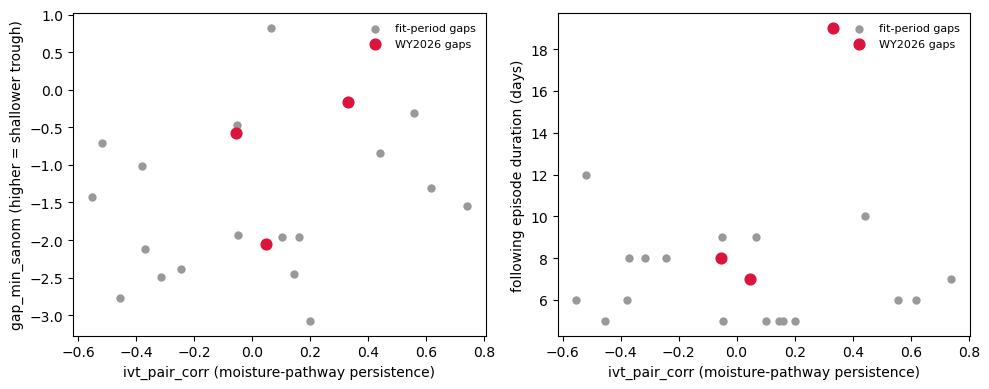

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(fit_gaps.ivt_pair_corr, fit_gaps.gap_min_sanom, c='0.6', s=25, label='fit-period gaps')
ax[0].scatter(sub_2026.ivt_pair_corr, sub_2026.gap_min_sanom, c='crimson', s=60, label='WY2026 gaps', zorder=3)
ax[0].set_xlabel('ivt_pair_corr (moisture-pathway persistence)')
ax[0].set_ylabel('gap_min_sanom (higher = shallower trough)')
ax[0].legend(frameon=False, fontsize=8)

ax[1].scatter(fit_gaps.ivt_pair_corr, fit_gaps.following_duration, c='0.6', s=25, label='fit-period gaps')
ax[1].scatter(sub_2026.ivt_pair_corr, sub_2026.following_duration, c='crimson', s=60, label='WY2026 gaps', zorder=3)
ax[1].set_xlabel('ivt_pair_corr (moisture-pathway persistence)')
ax[1].set_ylabel('following episode duration (days)')
ax[1].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()


## 8. Conclusion

**The join does not hold -- the two findings appear to be statistically independent of each other, not two signatures of the same mechanism.**

- **All six population-level tests are null.** Neither `ivt_pair_corr` (the hypothesis) nor `z300_pair_corr` (the dynamical control) correlates with gap depth or following-episode duration at n=18 fit-period gaps: p ranges from 0.08 to 0.90, and nothing clears even a nominal 0.05 bar, let alone the 6-test Bonferroni bar (p<0.0083). The closest result (`z300_pair_corr` vs. `gap_frac_below_neg1`, p=0.084) is the *control* variable, not the hypothesized one, and still doesn't reach nominal significance.
- **Pathway persistence is not a proxy for trough depth -- the collinearity check is itself informative.** `ivt_pair_corr` vs. `gap_min_sanom` across the same 18 gaps: rho=0.11, p=0.663 -- essentially uncorrelated. This directly answers the motivating question: the gap-trough-depth notebook's duration relationship and the central-Pacific-template notebook's season-wide IVT similarity are not two views of one underlying "background state stayed fixed" mechanism. At the population level, whether a gap's trough was shallow and whether the moisture pathway persisted across it vary independently.
- **WY2026's own three gaps don't tell a clean story either.** Only the gap immediately preceding March (Feb 23-Mar 10 onset-to-onset) pairs an elevated `ivt_pair_corr` (0.33, 78th percentile) with its shallow trough (94th percentile) -- but the *dynamical* control is elevated for that same gap too (`z300_pair_corr`=0.63, also 78th percentile), undercutting a moisture-specific reading for this one case. The other two WY2026 gaps show no such alignment: the Jan-to-Late-Jan/Feb gap has below-median pathway persistence (39th percentile) despite a moderately shallow trough (83rd percentile), and the Late-Jan/Feb-to-Late-Feb gap -- WY2026's one genuinely deep trough (33rd percentile, the "real exception" already noted in `CA_ridging_persistence_gap_trough_depth.ipynb`) -- has exactly median pathway persistence (50th percentile), not the suppressed value a "conveyor prevents troughs" story would predict.
- **This is consistent with, not contradictory to, the original template-notebook finding -- it just locates where that finding's signal actually lives.** The three `ivt_pair_corr` values computed here (-0.06, 0.05, 0.33) reproduce exactly the three *consecutive* pairs among the six pairwise correlations `CA_ridging_persistence_central_pacific_template.ipynb` reported (confirming this notebook's precursor computation matches), including the near-zero Jan/Late-Jan-Feb pair that notebook called out explicitly. But that notebook's overall 91st-percentile result (mean pairwise correlation 0.238 across all six pairs) was therefore not driven uniformly by adjacent-episode persistence -- it also reflects the three *non-adjacent* pairs (Jan-vs-Late-Feb, Jan-vs-March, Late-Jan/Feb-vs-March), which this notebook didn't examine. So "the moisture pathway was unusually consistent across WY2026" and "the moisture pathway specifically persisted across each individual gap" are different claims, and only the weaker, season-wide version of the first is actually supported.

**Net effect on the open mechanism question.** This join was a reasonable thing to test -- two real, independently-discovered signals in the same record, sharing the same intuitive story -- but testing it directly shows they don't combine into a single mechanism. The gap-trough-depth relationship and the central-Pacific IVT-similarity finding should continue to be treated as two separate, individually-suggestive-but-unconfirmed leads, not components of one explanation. Nothing here overturns either prior finding on its own terms; it specifically rules out the idea that one is *explained by* the other.